# KeySense AI — Existing Experiments and Session 2 Evaluation

**Important:** The original cells below use `dataset/spectrogram_images/manifest.csv` and train/test on a random split. Avoid running cell 2 (it rewrites the old manifest labels) if you want to preserve the existing dataset. The added Session 2 evaluation cells at the end load the saved CNN and test it on `dataset/session2/manifest.csv` without retraining.

Before running the Session 2 evaluation, make sure `SoundToSonoGraph_fixed.ipynb` has completed successfully and the Session 2 manifest exists.

In [3]:
import pandas as pd
import numpy as np
from PIL import Image

manifest = pd.read_csv(
    "./dataset/session2/manifest.csv"
)

# Keep only rows with confirmed labels
manifest = manifest.dropna(subset=["label"])
manifest = manifest[manifest["label"].astype(str).str.strip() != ""]

X = np.array([
    np.asarray(
        Image.open(path).convert("L"),
        dtype=np.float32
    ).flatten() / 255.0
    for path in manifest["image_path"]
])

y = manifest["label"].astype(str).to_numpy()

print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Classes:", np.unique(y))

Feature matrix: (3070, 16384)
Labels: (3070,)
Classes: ['A' 'B' 'C' 'D' 'E' 'F' 'G' 'H' 'I' 'J' 'K' 'L' 'M' 'N' 'O' 'P' 'Q' 'R'
 'S' 'T' 'U' 'V' 'W' 'X' 'Y' 'Z']


In [5]:
import pandas as pd
from pathlib import Path

manifest_path = Path("./dataset/session2/manifest.csv")
manifest = pd.read_csv(manifest_path)

print("Total manifest rows:", len(manifest))
print("\nColumns:", manifest.columns.tolist())
print("\nFirst five rows:")
display(manifest.head())

print("\nLabels:")
print(manifest["label"].value_counts(dropna=False))

print("\nExisting image files:", sum(
    Path(p).exists() for p in manifest["image_path"]
))

Total manifest rows: 3070

Columns: ['image_path', 'audio_path', 'source_recording', 'label', 'session_id', 'start_seconds', 'end_seconds']

First five rows:


,image_path,audio_path,source_recording,label,session_id,start_seconds,end_seconds
0,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_001.wav,A.mp3,A,session2,0.4056,0.7304
1,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_002.wav,A.mp3,A,session2,0.5976,0.9032
2,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_003.wav,A.mp3,A,session2,1.3272,1.6552
3,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_004.wav,A.mp3,A,session2,1.5352,1.8440
4,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_005.wav,A.mp3,A,session2,2.3896,2.7272



Labels:
label
C    156
S    150
O    142
G    140
R    136
I    135
T    131
J    129
E    128
X    127
A    126
Z    123
B    119
M    119
D    114
P    114
L    112
U    110
K    109
Q    101
H    100
W     99
F     94
V     92
Y     85
N     79
Name: count, dtype: int64

Existing image files: 3070


In [7]:
import pandas as pd
from pathlib import Path

manifest_path = Path("./dataset/session2/manifest.csv")

manifest = pd.read_csv(manifest_path)

# Assign each image the key named by its source folder
manifest["label"] = (
    manifest["source_recording"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Save the corrected manifest
manifest.to_csv(manifest_path, index=False)

print("Total images:", len(manifest))
print("\nImages per key:")
print(manifest["label"].value_counts().sort_index())

print("\nSample rows:")
display(manifest.head())

Total images: 3070

Images per key:
label
A.MP3    126
B.MP3    119
C.MP3    156
D.MP3    114
E.MP3    128
F.MP3     94
G.MP3    140
H.MP3    100
I.MP3    135
J.MP3    129
K.MP3    109
L.MP3    112
M.MP3    119
N.MP3     79
O.MP3    142
P.MP3    114
Q.MP3    101
R.MP3    136
S.MP3    150
T.MP3    131
U.MP3    110
V.MP3     92
W.MP3     99
X.MP3    127
Y.MP3     85
Z.MP3    123
Name: count, dtype: int64

Sample rows:


,image_path,audio_path,source_recording,label,session_id,start_seconds,end_seconds
0,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_001.wav,A.mp3,A.MP3,session2,0.4056,0.7304
1,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_002.wav,A.mp3,A.MP3,session2,0.5976,0.9032
2,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_003.wav,A.mp3,A.MP3,session2,1.3272,1.6552
3,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_004.wav,A.mp3,A.MP3,session2,1.5352,1.8440
4,dataset/session2/spectrogram_images/A/event_00...,dataset/session2/detected/A/event_005.wav,A.mp3,A.MP3,session2,2.3896,2.7272


In [8]:
import numpy as np
from PIL import Image

X = np.stack([
    np.asarray(
        Image.open(path).convert("L").resize((128, 128)),
        dtype=np.float32
    ).flatten() / 255.0
    for path in manifest["image_path"]
])

y = manifest["label"].to_numpy()

print("Feature matrix X:", X.shape)
print("Labels y:", y.shape)
print("Classes:", np.unique(y))

Feature matrix X: (3070, 16384)
Labels y: (3070,)
Classes: ['A.MP3' 'B.MP3' 'C.MP3' 'D.MP3' 'E.MP3' 'F.MP3' 'G.MP3' 'H.MP3' 'I.MP3'
 'J.MP3' 'K.MP3' 'L.MP3' 'M.MP3' 'N.MP3' 'O.MP3' 'P.MP3' 'Q.MP3' 'R.MP3'
 'S.MP3' 'T.MP3' 'U.MP3' 'V.MP3' 'W.MP3' 'X.MP3' 'Y.MP3' 'Z.MP3']


In [9]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Check class distribution first
print("Samples per key:")
print(pd.Series(y).value_counts().sort_index())

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining samples per key:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting samples per key:")
print(pd.Series(y_test).value_counts().sort_index())

Samples per key:
A.MP3    126
B.MP3    119
C.MP3    156
D.MP3    114
E.MP3    128
F.MP3     94
G.MP3    140
H.MP3    100
I.MP3    135
J.MP3    129
K.MP3    109
L.MP3    112
M.MP3    119
N.MP3     79
O.MP3    142
P.MP3    114
Q.MP3    101
R.MP3    136
S.MP3    150
T.MP3    131
U.MP3    110
V.MP3     92
W.MP3     99
X.MP3    127
Y.MP3     85
Z.MP3    123
Name: count, dtype: int64

Training shape: (2456, 16384)
Testing shape: (614, 16384)

Training samples per key:
A.MP3    101
B.MP3     95
C.MP3    125
D.MP3     91
E.MP3    102
F.MP3     75
G.MP3    112
H.MP3     80
I.MP3    108
J.MP3    103
K.MP3     87
L.MP3     90
M.MP3     95
N.MP3     63
O.MP3    114
P.MP3     91
Q.MP3     81
R.MP3    109
S.MP3    120
T.MP3    105
U.MP3     88
V.MP3     74
W.MP3     79
X.MP3    102
Y.MP3     68
Z.MP3     98
Name: count, dtype: int64

Testing samples per key:
A.MP3    25
B.MP3    24
C.MP3    31
D.MP3    23
E.MP3    26
F.MP3    19
G.MP3    28
H.MP3    20
I.MP3    27
J.MP3    26
K.MP3    22
L.MP3    22

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize using training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Retain 95% of the variance
pca = PCA(
    n_components=0.95,
    random_state=42
)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("PCA features:", X_train_pca.shape[1])
print(
    f"Explained variance retained: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Original features: 16384
PCA features: 755
Explained variance retained: 95.01%


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# PCA retains 95% of training-set variance
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print("Variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Train ANN
ann = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    solver="adam",
    alpha=0.001,
    batch_size=32,
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=42
)

start = time.time()
ann.fit(X_train_pca, y_train)
training_time = time.time() - start

y_pred = ann.predict(X_test_pca)

print(f"\nTraining time: {training_time:.2f} seconds")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, zero_division=0))

Original features: 16384
Features after PCA: 755
Variance retained: 95.01 %

Training time: 8.30 seconds
Test accuracy: 0.8730
              precision    recall  f1-score   support

       A.MP3       1.00      0.88      0.94        25
       B.MP3       0.88      0.96      0.92        24
       C.MP3       0.82      0.90      0.86        31
       D.MP3       0.88      1.00      0.94        23
       E.MP3       0.81      0.96      0.88        26
       F.MP3       1.00      0.95      0.97        19
       G.MP3       1.00      0.79      0.88        28
       H.MP3       0.94      0.85      0.89        20
       I.MP3       0.93      0.96      0.95        27
       J.MP3       0.83      0.77      0.80        26
       K.MP3       0.73      0.86      0.79        22
       L.MP3       0.85      0.77      0.81        22
       M.MP3       0.80      0.83      0.82        24
       N.MP3       0.79      0.69      0.73        16
       O.MP3       0.83      0.68      0.75        28
       P

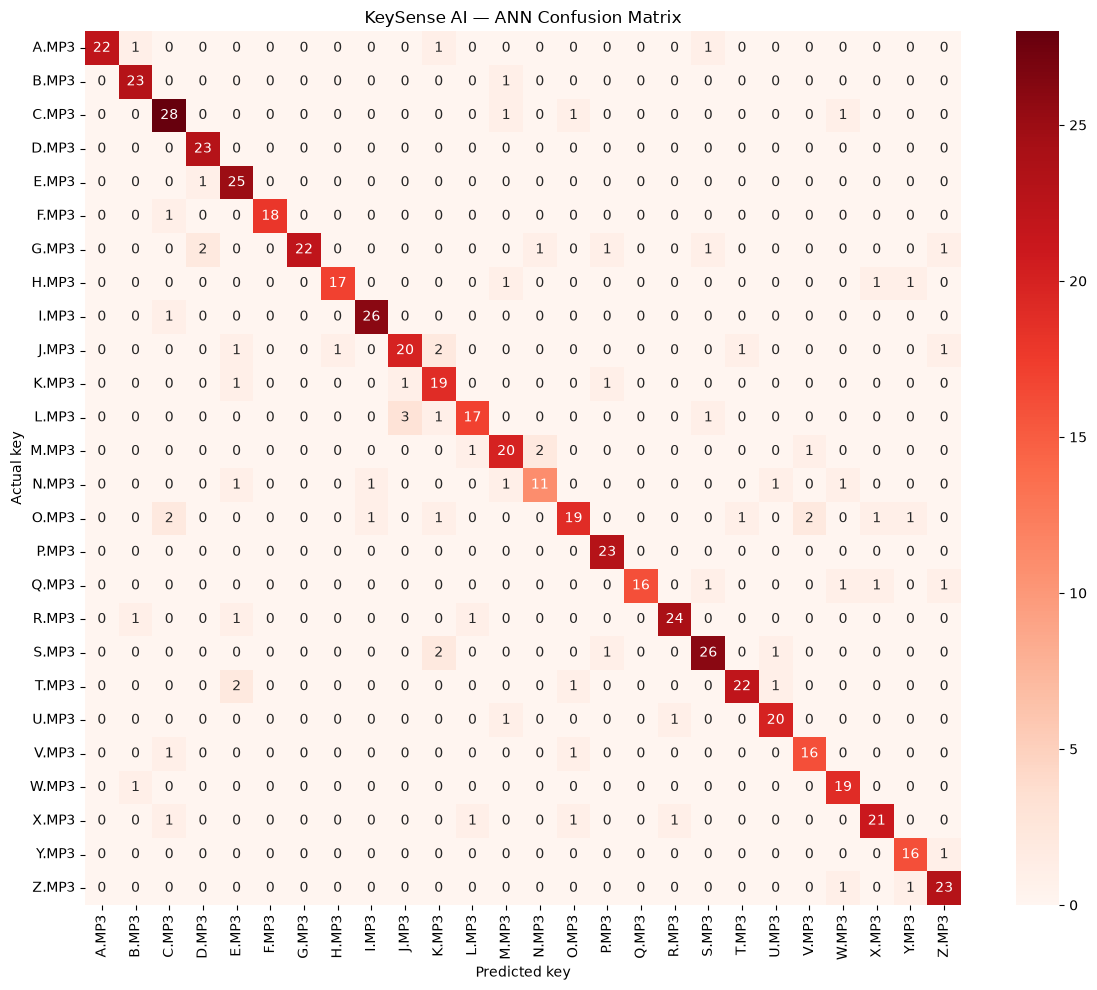

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

labels = sorted(np.unique(np.concatenate([y_test, y_pred])))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted key")
plt.ylabel("Actual key")
plt.title("KeySense AI — ANN Confusion Matrix")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    balanced_accuracy_score
)

print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1:          {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nPer-key performance:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:          0.8730
Balanced accuracy: 0.8733
Macro F1:          0.8720

Per-key performance:
              precision    recall  f1-score   support

       A.MP3       1.00      0.88      0.94        25
       B.MP3       0.88      0.96      0.92        24
       C.MP3       0.82      0.90      0.86        31
       D.MP3       0.88      1.00      0.94        23
       E.MP3       0.81      0.96      0.88        26
       F.MP3       1.00      0.95      0.97        19
       G.MP3       1.00      0.79      0.88        28
       H.MP3       0.94      0.85      0.89        20
       I.MP3       0.93      0.96      0.95        27
       J.MP3       0.83      0.77      0.80        26
       K.MP3       0.73      0.86      0.79        22
       L.MP3       0.85      0.77      0.81        22
       M.MP3       0.80      0.83      0.82        24
       N.MP3       0.79      0.69      0.73        16
       O.MP3       0.83      0.68      0.75        28
       P.MP3       0.88      1.00  

In [14]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

ann_raw = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    max_iter=200,
    early_stopping=True,
    random_state=42
)

start = time.time()
ann_raw.fit(X_train, y_train)
raw_time = time.time() - start

raw_pred = ann_raw.predict(X_test)

print("ANN without PCA")
print(f"Accuracy: {accuracy_score(y_test, raw_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, raw_pred, average='macro'):.4f}")
print(f"Training time: {raw_time:.2f} seconds")

print("\nANN with PCA")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

ANN without PCA
Accuracy: 0.8941
Macro F1: 0.8949
Training time: 50.74 seconds

ANN with PCA
Accuracy: 0.8730
Macro F1: 0.8720


In [17]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Load labeled manifest
manifest = pd.read_csv("./dataset/session2/manifest.csv")
manifest = manifest.dropna(subset=["label", "image_path"]).copy()

manifest["label"] = manifest["label"].astype(str).str.strip().str.upper()
manifest = manifest[manifest["label"] != ""]

# Load grayscale spectrograms
images = []

for path in manifest["image_path"]:
    with Image.open(path) as img:
        img = img.convert("L").resize((128, 128))
        images.append(np.asarray(img, dtype=np.float32) / 255.0)

X_cnn = np.array(images)[..., np.newaxis]

encoder = LabelEncoder()
y_cnn = encoder.fit_transform(manifest["label"])

print("Images:", X_cnn.shape)
print("Labels:", y_cnn.shape)
print("Classes:", list(encoder.classes_))

Images: (3070, 128, 128, 1)
Labels: (3070,)
Classes: ['A.MP3', 'B.MP3', 'C.MP3', 'D.MP3', 'E.MP3', 'F.MP3', 'G.MP3', 'H.MP3', 'I.MP3', 'J.MP3', 'K.MP3', 'L.MP3', 'M.MP3', 'N.MP3', 'O.MP3', 'P.MP3', 'Q.MP3', 'R.MP3', 'S.MP3', 'T.MP3', 'U.MP3', 'V.MP3', 'W.MP3', 'X.MP3', 'Y.MP3', 'Z.MP3']


In [18]:

indices = np.arange(len(y_cnn))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y_cnn
)

X_train_cnn = X_cnn[train_idx]
X_test_cnn = X_cnn[test_idx]

y_train_cnn = y_cnn[train_idx]
y_test_cnn = y_cnn[test_idx]

print("Training images:", X_train_cnn.shape)
print("Testing images:", X_test_cnn.shape)

Training images: (2456, 128, 128, 1)
Testing images: (614, 128, 128, 1)


In [19]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

num_classes = len(encoder.classes_)

cnn = Sequential([
    Input(shape=(128, 128, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,290,714 (16.37 MB)

 Trainable params: 4,290,586 (16.37 MB)

 Non-trainable params: 128 (512.00 B)

In [20]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

num_classes = len(encoder.classes_)

cnn = Sequential([
    Input(shape=(128, 128, 1)),

    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu", padding="same"),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(num_classes, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,290,714 (16.37 MB)

 Trainable params: 4,290,586 (16.37 MB)

 Non-trainable params: 128 (512.00 B)

In [21]:
from tensorflow.keras.callbacks import EarlyStopping
import time

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

start = time.time()

history = cnn.fit(
    X_train_cnn,
    y_train_cnn,
    epochs=40,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stop],
    verbose=1
)

cnn_training_time = time.time() - start

print(f"\nTraining time: {cnn_training_time:.2f} seconds")

Epoch 1/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 114ms/step - accuracy: 0.0666 - loss: 3.2758 - val_accuracy: 0.0244 - val_loss: 3.2561
Epoch 2/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.1188 - loss: 2.9520 - val_accuracy: 0.2195 - val_loss: 3.2297
Epoch 3/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 115ms/step - accuracy: 0.2022 - loss: 2.6393 - val_accuracy: 0.2412 - val_loss: 3.2007
Epoch 4/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.2731 - loss: 2.3479 - val_accuracy: 0.3279 - val_loss: 3.1072
Epoch 5/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 8s 120ms/step - accuracy: 0.3431 - loss: 2.1031 - val_accuracy: 0.5312 - val_loss: 2.8615
Epoch 6/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - accuracy: 0.3651 - loss: 1.9486 - val_accuracy: 0.6152 - val_loss: 2.5913
Epoch 7/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 104ms/step - accuracy: 0.4293 - loss: 1.7109 - val_accuracy: 0.6043 - val_loss: 2.2004
Epoch 8/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 107ms/step - accuracy: 0.4701 - loss: 1.5582 - val_accuracy: 0.

In [22]:
probabilities = cnn.predict(X_test_cnn, verbose=0)
y_pred_cnn = np.argmax(probabilities, axis=1)

print(f"CNN accuracy: {accuracy_score(y_test_cnn, y_pred_cnn):.4f}")
print(
    f"CNN macro F1: "
    f"{f1_score(y_test_cnn, y_pred_cnn, average='macro'):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_test_cnn,
    y_pred_cnn,
    labels=np.arange(num_classes),
    target_names=encoder.classes_,
    zero_division=0
))

CNN accuracy: 0.8746
CNN macro F1: 0.8747

Classification report:
              precision    recall  f1-score   support

       A.MP3       0.96      0.88      0.92        25
       B.MP3       1.00      0.83      0.91        24
       C.MP3       0.67      0.90      0.77        31
       D.MP3       0.92      1.00      0.96        23
       E.MP3       0.88      0.85      0.86        26
       F.MP3       1.00      0.74      0.85        19
       G.MP3       0.89      0.86      0.87        28
       H.MP3       0.94      0.80      0.86        20
       I.MP3       0.96      0.96      0.96        27
       J.MP3       0.96      0.92      0.94        26
       K.MP3       0.77      0.77      0.77        22
       L.MP3       0.78      0.82      0.80        22
       M.MP3       0.90      0.79      0.84        24
       N.MP3       0.75      0.94      0.83        16
       O.MP3       0.92      0.79      0.85        28
       P.MP3       0.88      0.91      0.89        23
       Q.MP3   

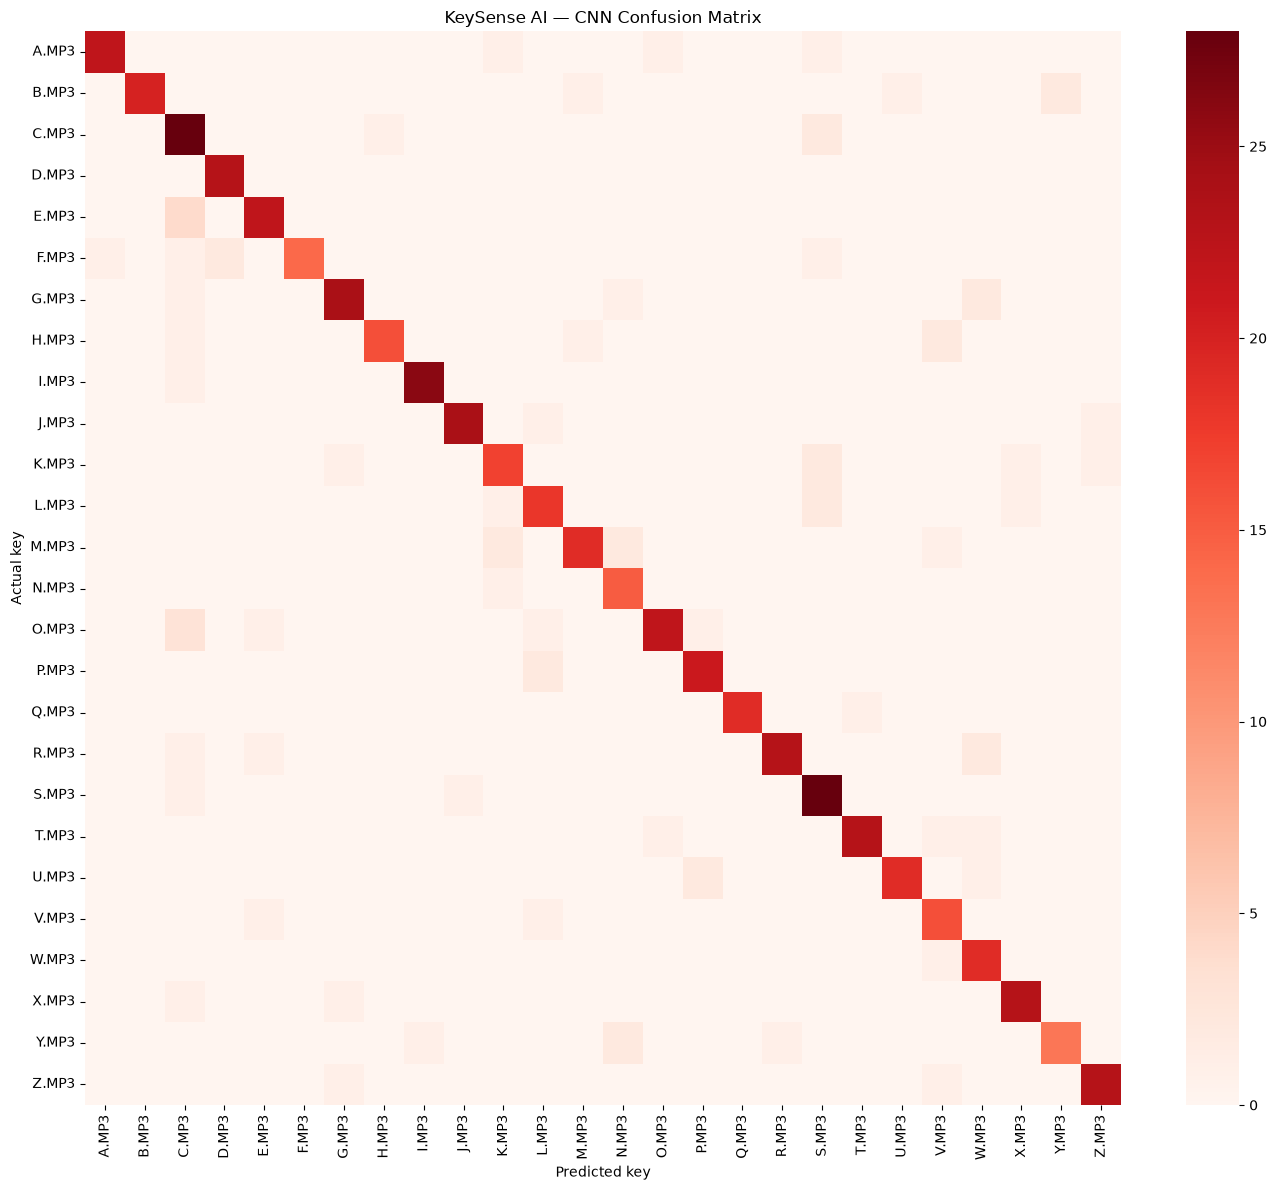

In [23]:
cm = confusion_matrix(
    y_test_cnn,
    y_pred_cnn,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 12))
import seaborn as sns

sns.heatmap(
    cm,
    cmap="Reds",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("KeySense AI — CNN Confusion Matrix")
plt.xlabel("Predicted key")
plt.ylabel("Actual key")
plt.tight_layout()
plt.show()

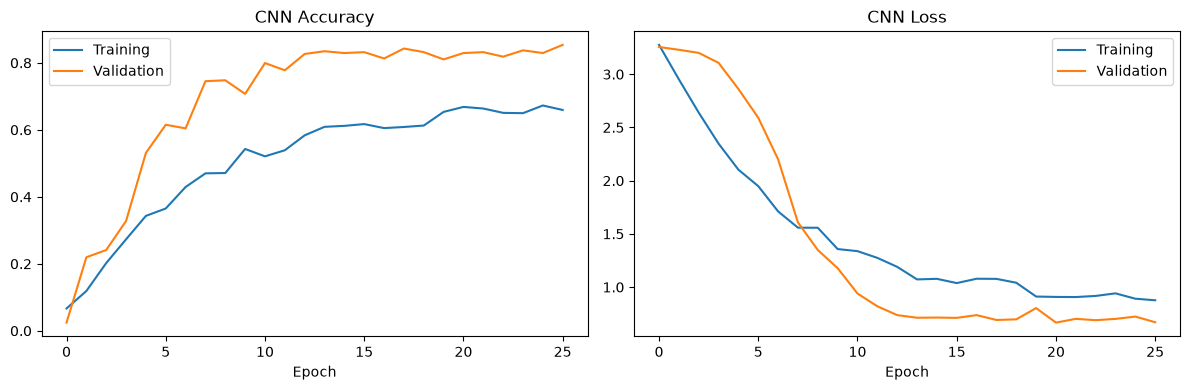

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [25]:
[name for name in globals()
 if "encoder" in name.lower() or name == "le"]

['LabelEncoder', 'encoder']

In [26]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

cnn_accuracy = accuracy_score(y_test_cnn, y_pred_cnn)
cnn_macro_f1 = f1_score(y_test_cnn, y_pred_cnn, average="macro")

print(f"CNN Test Accuracy: {cnn_accuracy:.4f}")
print(f"CNN Macro F1:      {cnn_macro_f1:.4f}")

print(classification_report(
    y_test_cnn,
    y_pred_cnn,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

CNN Test Accuracy: 0.8746
CNN Macro F1:      0.8747
              precision    recall  f1-score   support

       A.MP3       0.96      0.88      0.92        25
       B.MP3       1.00      0.83      0.91        24
       C.MP3       0.67      0.90      0.77        31
       D.MP3       0.92      1.00      0.96        23
       E.MP3       0.88      0.85      0.86        26
       F.MP3       1.00      0.74      0.85        19
       G.MP3       0.89      0.86      0.87        28
       H.MP3       0.94      0.80      0.86        20
       I.MP3       0.96      0.96      0.96        27
       J.MP3       0.96      0.92      0.94        26
       K.MP3       0.77      0.77      0.77        22
       L.MP3       0.78      0.82      0.80        22
       M.MP3       0.90      0.79      0.84        24
       N.MP3       0.75      0.94      0.83        16
       O.MP3       0.92      0.79      0.85        28
       P.MP3       0.88      0.91      0.89        23
       Q.MP3       1.00      

---

## Session 2: Evaluate the existing CNN on unseen recordings

Run these cells **after** the Session 2 processing notebook has produced `dataset/session2/manifest.csv` and after you have saved your already-trained CNN and label encoder. If you haven't saved them yet, use the save cell below while the original notebook still has `cnn` and `encoder` in memory.

This evaluation does not train or fine-tune the model on Session 2.

In [27]:
# OPTIONAL: run this in the original notebook kernel if `cnn` and `encoder`
# are still in memory. It saves the existing model and its class mapping.
from pathlib import Path
import joblib

MODEL_DIR = Path("./models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

cnn.save(MODEL_DIR / "keysense_cnn.keras")
joblib.dump(encoder, MODEL_DIR / "keysense_label_encoder.joblib")

print("Saved existing CNN and label encoder.")
print("Model:", (MODEL_DIR / "keysense_cnn.keras").resolve())
print("Encoder:", (MODEL_DIR / "keysense_label_encoder.joblib").resolve())

Saved existing CNN and label encoder.
Model: C:\Users\My Pc\Desktop\Code\keyboard sound detection\models\keysense_cnn.keras
Encoder: C:\Users\My Pc\Desktop\Code\keyboard sound detection\models\keysense_label_encoder.joblib


In [28]:
# Load the saved CNN and encoder, then load ONLY Session 2's manifest.
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

MODEL_PATH = Path("./models/keysense_cnn.keras")
ENCODER_PATH = Path("./models/keysense_label_encoder.joblib")
SESSION2_MANIFEST = Path("./dataset/session2/manifest.csv")

for required_path in [MODEL_PATH, ENCODER_PATH, SESSION2_MANIFEST]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Missing required file: {required_path.resolve()}\n"
            "First process Session 2 and save the existing CNN/encoder."
        )

cnn_session2 = tf.keras.models.load_model(MODEL_PATH)
encoder_session2 = joblib.load(ENCODER_PATH)

session2 = pd.read_csv(SESSION2_MANIFEST)
session2 = session2.dropna(subset=["image_path", "label"]).copy()
session2["label"] = session2["label"].astype(str).str.strip().str.upper()
session2 = session2[session2["label"] != ""]

# Keep only labels known to the trained encoder.
known_labels = set(encoder_session2.classes_)
unknown_labels = sorted(set(session2["label"]) - known_labels)
if unknown_labels:
    print("Warning: skipping labels not known to the trained model:", unknown_labels)
session2 = session2[session2["label"].isin(known_labels)].reset_index(drop=True)

if session2.empty:
    raise ValueError("No Session 2 rows remain with valid images and known labels.")

missing_images = [p for p in session2["image_path"] if not Path(p).exists()]
if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images)} image path(s) in Session 2 manifest do not exist. "
        f"Example: {missing_images[0]}"
    )

X_session2 = np.stack([
    np.asarray(Image.open(p).convert("L").resize((128, 128)), dtype=np.float32) / 255.0
    for p in session2["image_path"]
])[..., np.newaxis]

y_session2 = encoder_session2.transform(session2["label"])

print("Session 2 images:", X_session2.shape)
print("Session 2 samples per key:")
display(session2["label"].value_counts().sort_index().rename("samples").to_frame())

Session 2 images: (3070, 128, 128, 1)
Session 2 samples per key:


,samples
label,
A.MP3,126
B.MP3,119
C.MP3,156
D.MP3,114
E.MP3,128
F.MP3,94
G.MP3,140
H.MP3,100
I.MP3,135


Session 2 accuracy: 0.9430
Session 2 macro F1: 0.9429

Per-key report:
              precision    recall  f1-score   support

       A.MP3       0.96      0.96      0.96       126
       B.MP3       0.98      0.89      0.93       119
       C.MP3       0.88      0.93      0.91       156
       D.MP3       0.96      0.96      0.96       114
       E.MP3       0.96      0.95      0.96       128
       F.MP3       0.98      0.91      0.95        94
       G.MP3       0.92      0.97      0.94       140
       H.MP3       0.97      0.90      0.93       100
       I.MP3       0.95      0.99      0.97       135
       J.MP3       0.98      0.93      0.96       129
       K.MP3       0.92      0.90      0.91       109
       L.MP3       0.92      0.91      0.91       112
       M.MP3       0.95      0.95      0.95       119
       N.MP3       0.87      0.97      0.92        79
       O.MP3       0.94      0.92      0.93       142
       P.MP3       0.96      0.91      0.94       114
       Q.M

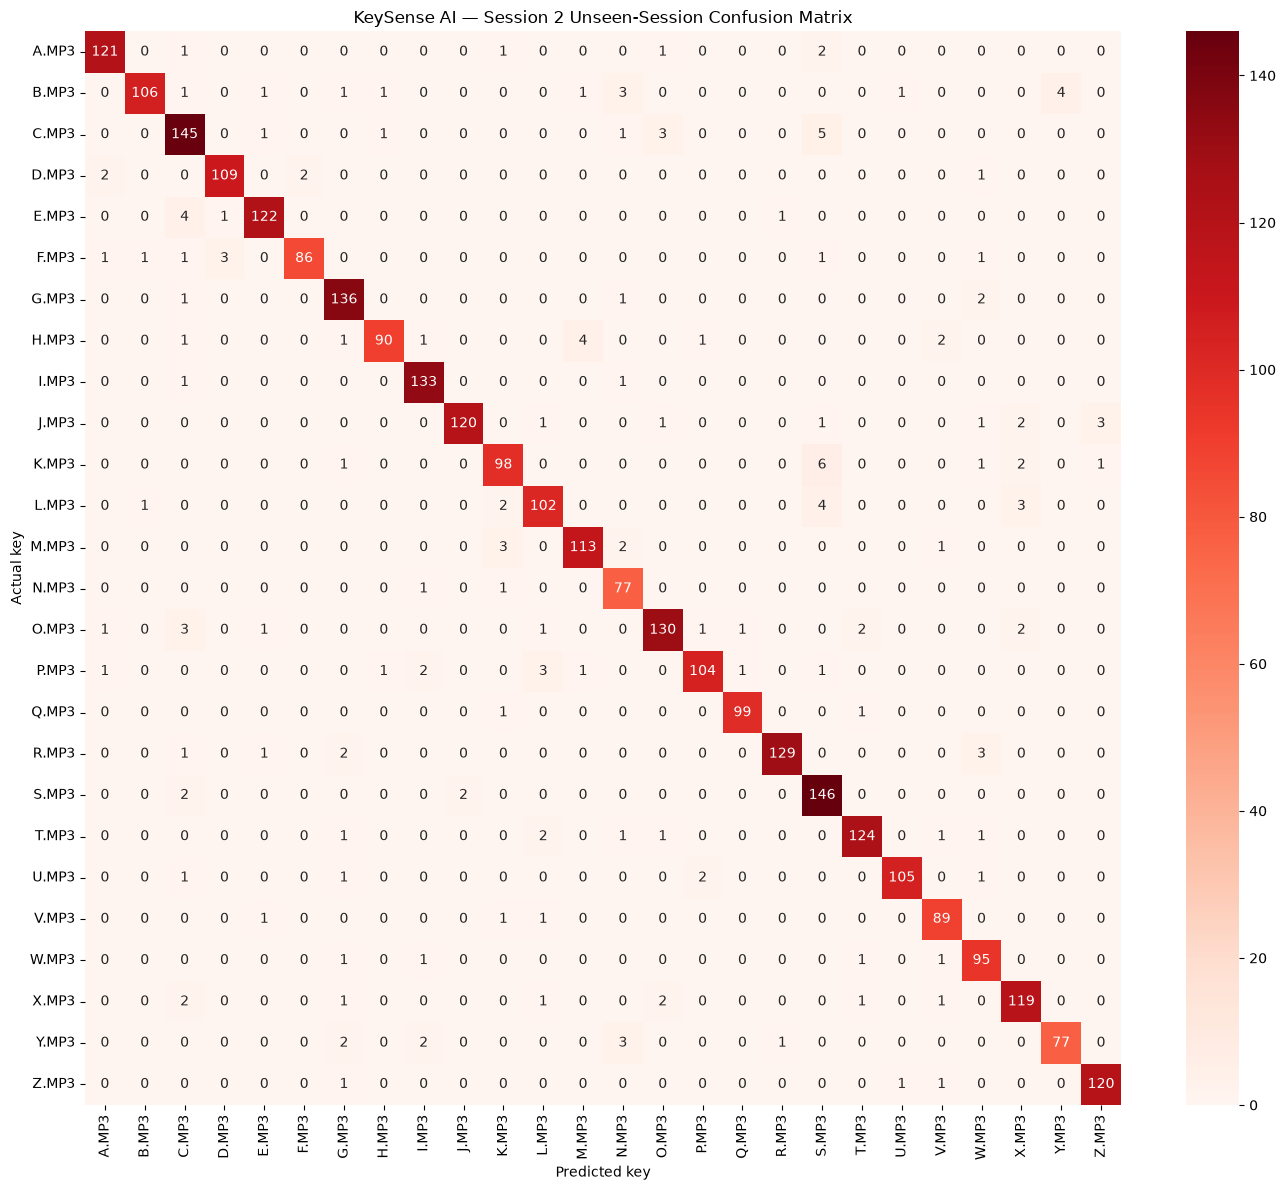

In [29]:
# Evaluate on Session 2 — no training occurs here.
probabilities_session2 = cnn_session2.predict(X_session2, verbose=0)
pred_session2 = np.argmax(probabilities_session2, axis=1)

print(f"Session 2 accuracy: {accuracy_score(y_session2, pred_session2):.4f}")
print(f"Session 2 macro F1: {f1_score(y_session2, pred_session2, average='macro', zero_division=0):.4f}")
print("\nPer-key report:")
print(classification_report(
    y_session2,
    pred_session2,
    labels=np.arange(len(encoder_session2.classes_)),
    target_names=encoder_session2.classes_,
    zero_division=0
))

cm_session2 = confusion_matrix(
    y_session2, pred_session2,
    labels=np.arange(len(encoder_session2.classes_))
)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 12))
sns.heatmap(
    cm_session2,
    annot=True,
    fmt="d",
    cmap="Reds",
    xticklabels=encoder_session2.classes_,
    yticklabels=encoder_session2.classes_
)
plt.title("KeySense AI — Session 2 Unseen-Session Confusion Matrix")
plt.xlabel("Predicted key")
plt.ylabel("Actual key")
plt.tight_layout()
plt.show()